# Student performance: feature investigation

Explore possible inputs for predicting `G3`, the final maths grade (0–20), using all 395 students in `student-mat.csv`. The charts compare grades, group sizes and possible splits.

This notebook investigates features only. Column exclusions are provisional: small differences in group averages do not prove a feature is useless, and these charts do not measure predictive accuracy.

## Setup

In [145]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

search_roots = [Path.cwd(), Path.cwd() / "student"]
DATA_PATH = next(p / "student-mat.csv" for p in search_roots if (p / "student-mat.csv").exists())
DATA_PATH

PosixPath('/Users/darraghflynn/dev/content/ML-assignment1/student/student-mat.csv')

## Load

Fields are separated with `;`. `G1` and `G2` are quoted, so check the dtypes and make the grades numeric.

In [146]:
df = pd.read_csv(DATA_PATH, sep=";")
for col in ("G1", "G2", "G3"):
    df[col] = pd.to_numeric(df[col])

print(f"{df.shape[0]} students, {df.shape[1]} columns")
print(f"missing values: {int(df.isna().sum().sum())}")
df.head()


395 students, 33 columns
missing values: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## Columns

Every column is listed here. The figure under it is one chart per column: a bar when there are only a few different values, a histogram otherwise.

In [147]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique": df.nunique(),
    "example": [df[col].dropna().iloc[0] for col in df.columns],
})
summary


,dtype,unique,example
school,str,2,GP
sex,str,2,F
age,int64,8,18
address,str,2,U
famsize,str,2,GT3
Pstatus,str,2,A
Medu,int64,5,4
Fedu,int64,5,4
Mjob,str,5,at_home
Fjob,str,5,teacher


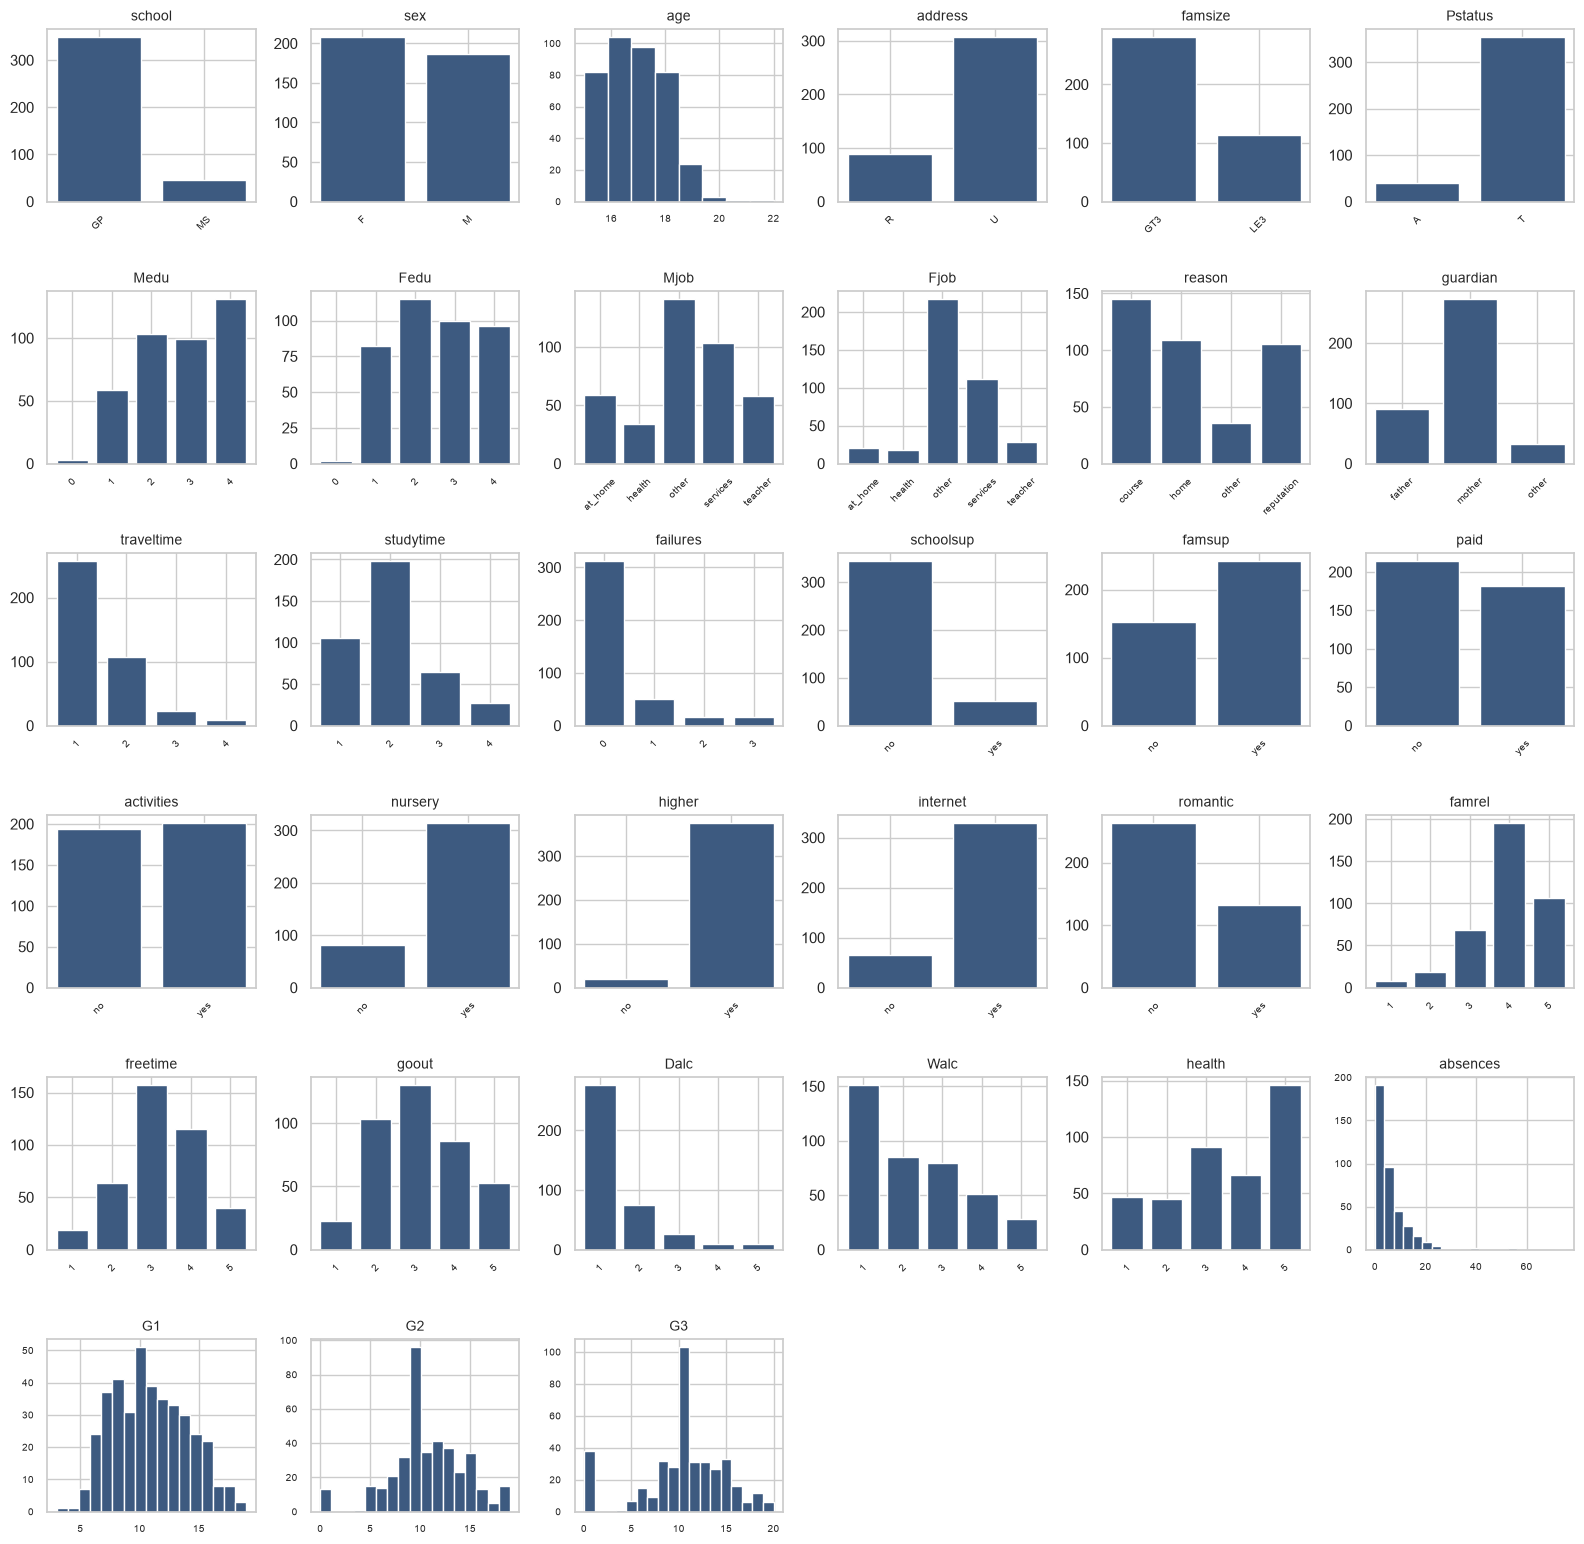

In [148]:
n = len(df.columns)
ncols = 6
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.6 * nrows))
axes = axes.ravel()

for ax, col in zip(axes, df.columns):
    s = df[col]
    few_values = (not pd.api.types.is_numeric_dtype(s)) or s.nunique() <= 5
    if few_values:
        counts = s.value_counts(dropna=False).sort_index()
        ax.bar(counts.index.astype(str), counts.values, color="#3d5a80")
        ax.tick_params(axis="x", labelrotation=45, labelsize=7)
    else:
        ax.hist(s.dropna(), bins=min(20, s.nunique()), color="#3d5a80")
        ax.tick_params(labelsize=7)
    ax.set_title(col, fontsize=10)

for ax in axes[n:]:
    ax.axis("off")

fig.tight_layout()
plt.show()


## Earlier grades

`G1` and `G2` are earlier marks in the same course and correlate strongly with `G3`. They are excluded to focus on background and study information.

      G1    G2   G3
G1  1.00  0.85  0.8
G2  0.85  1.00  0.9
G3  0.80  0.90  1.0


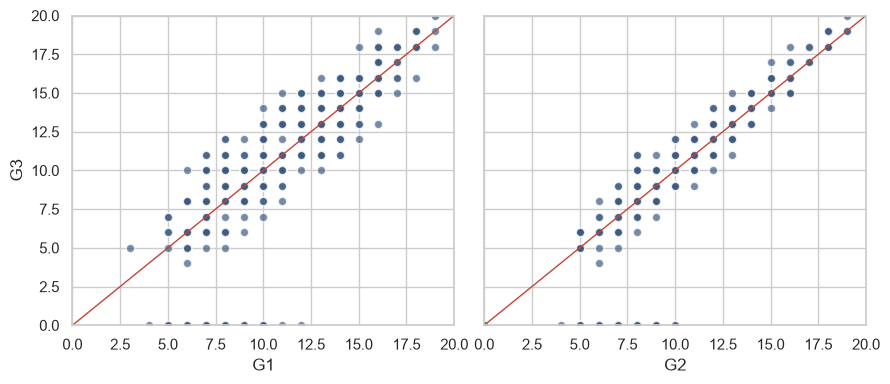

In [149]:
print(df[["G1", "G2", "G3"]].corr().round(2))

fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
for ax, col in zip(axes, ("G1", "G2")):
    ax.scatter(df[col], df["G3"], alpha=0.7, edgecolor="white", color="#3d5a80")
    ax.plot([0, 20], [0, 20], color="#c44536", linewidth=1)
    ax.set_xlabel(col)
    ax.set_xlim(0, 20)
    ax.set_ylim(0, 20)
axes[0].set_ylabel("G3")
fig.tight_layout()
plt.show()

In [150]:
y = df["G3"]
X = df.drop(columns=["G1", "G2", "G3"])
print(f"{X.shape[1]} columns left")

30 columns left


## One question per column

A tree starts by trying one yes/no question on each column and keeping the question that cuts the squared error the most. The bar below is that cut, for each column still in `X`.

A numeric column is split at a threshold (`failures <= 0`). A text column is split as one value against the rest (`higher` is `no`, or not). Both sides of the split need at least 15 students.

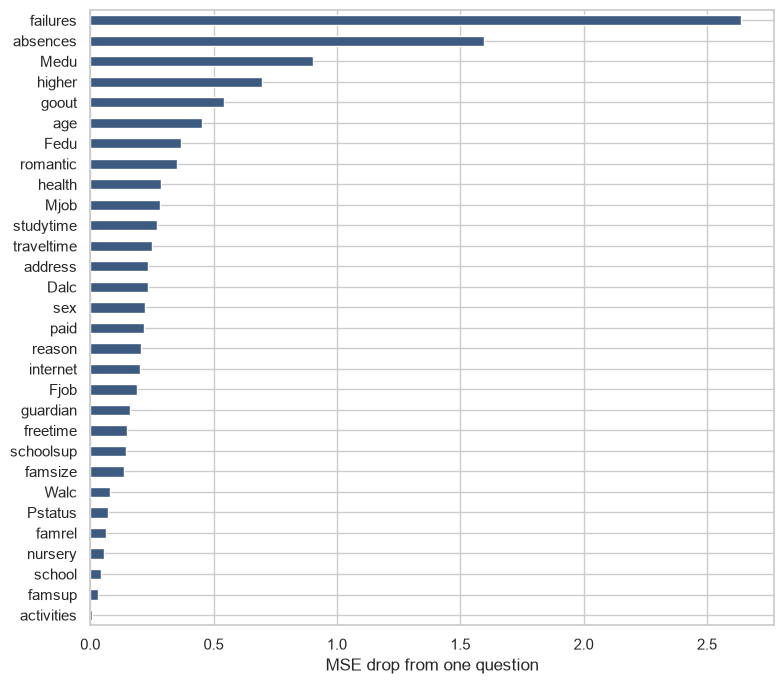

In [151]:
def one_split_gain(series, target, min_side=15):
    target = np.asarray(target, dtype=float)
    base = ((target - target.mean()) ** 2).mean()
    values = series.to_numpy()
    best = 0.0

    if pd.api.types.is_numeric_dtype(series):
        cuts = np.sort(series.unique())[:-1]
        masks = [values <= cut for cut in cuts]
    else:
        masks = [values == level for level in series.unique()]

    for left in masks:
        if left.sum() < min_side or (~left).sum() < min_side:
            continue
        pred = np.where(left, target[left].mean(), target[~left].mean())
        best = max(best, base - ((target - pred) ** 2).mean())
    return best


gain = pd.Series(
    {col: one_split_gain(X[col], y) for col in X.columns},
    name="mse_drop",
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
gain.sort_values().plot.barh(ax=ax, color="#3d5a80")
ax.set_xlabel("MSE drop from one question")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

## Average grade by value

Same columns, in that order. Each bar is the average `G3` for students with that value. The red line is the average for the whole file, about 10.4. The axis runs from 0 to 20 so a flat column looks flat.

Values with fewer than 5 students are left off. `absences` has too many different numbers for this grid, so it is binned on its own.

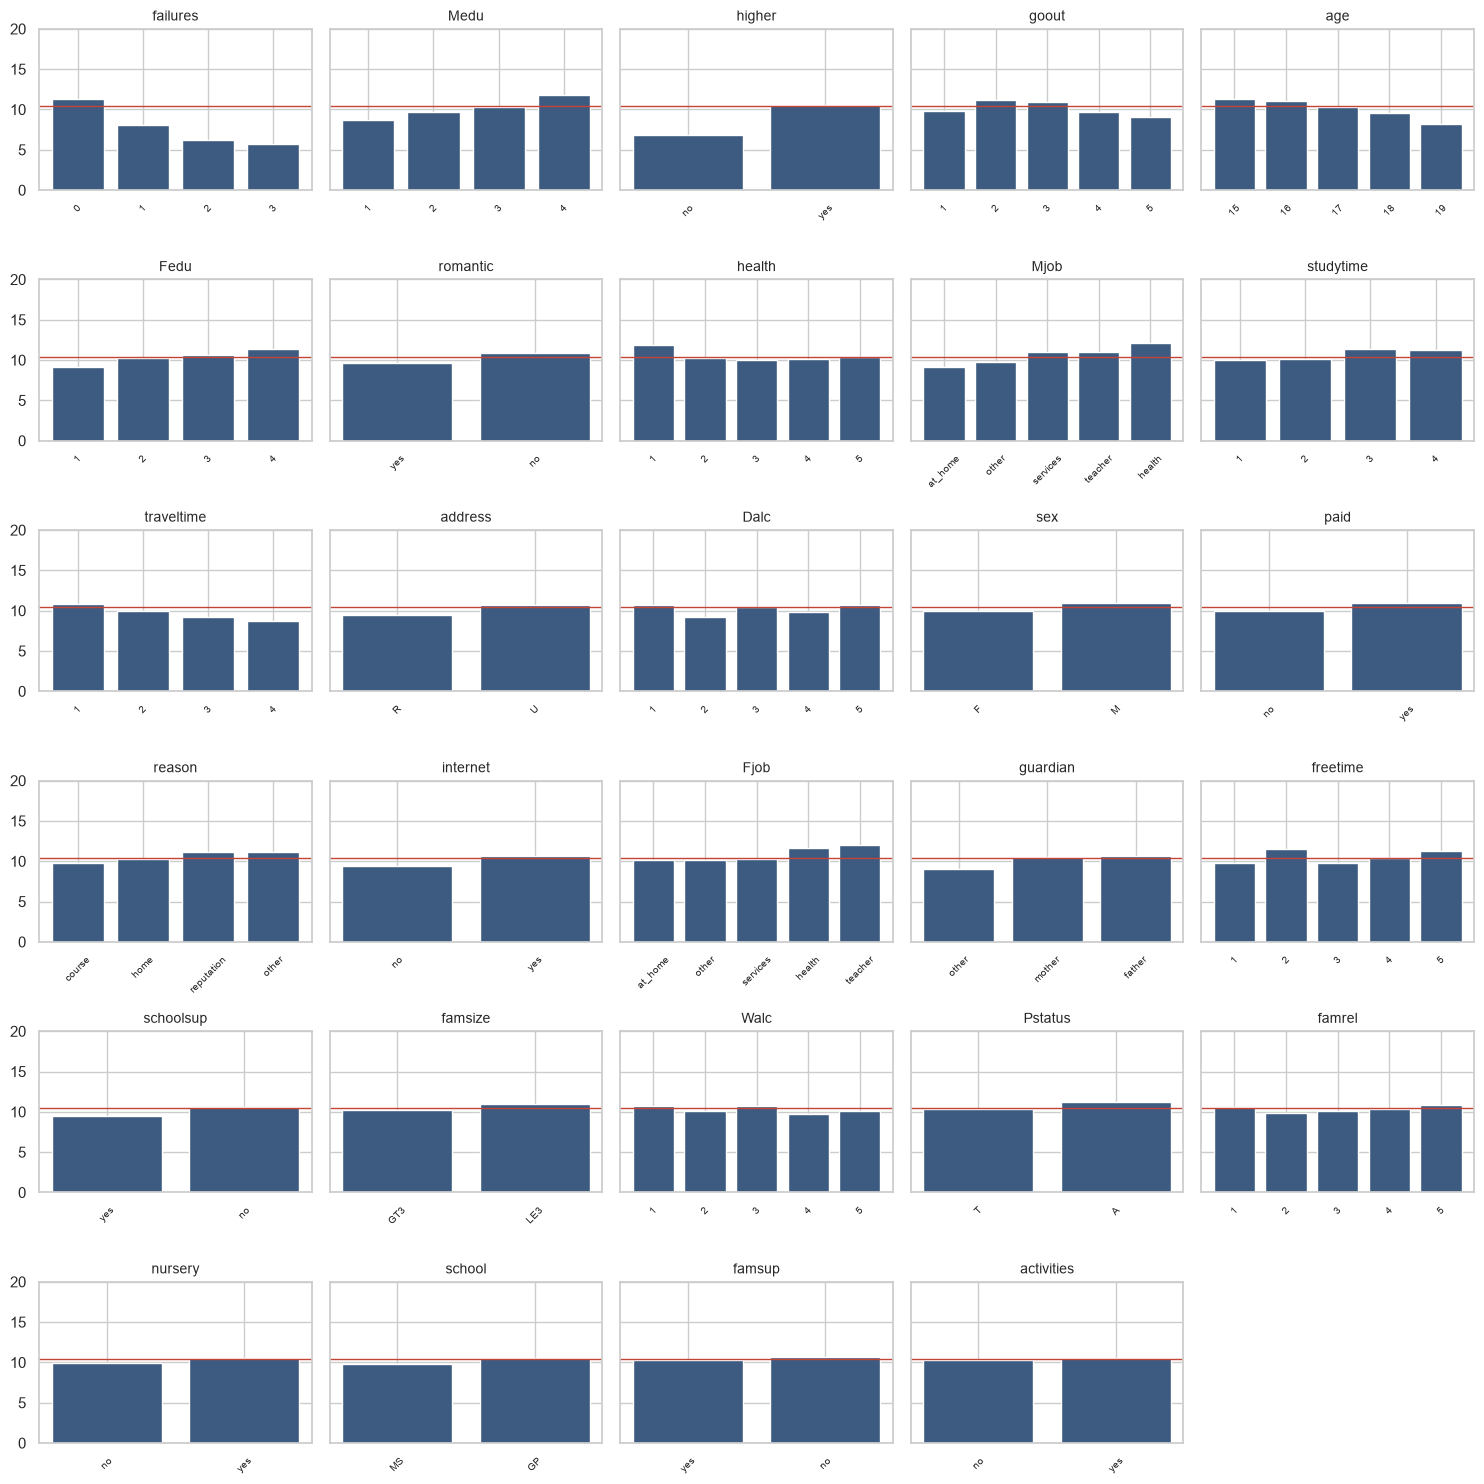

In [152]:
plot_cols = [col for col in gain.index if X[col].nunique() <= 8]
ncols = 5
nrows = (len(plot_cols) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 2.5 * nrows), sharey=True)
axes = axes.ravel()
overall = float(y.mean())

for ax, col in zip(axes, plot_cols):
    grouped = df.groupby(col, observed=True)["G3"].agg(["mean", "size"])
    grouped = grouped[grouped["size"] >= 5]
    if pd.api.types.is_numeric_dtype(X[col]):
        grouped = grouped.sort_index()
    else:
        grouped = grouped.sort_values("mean")
    ax.bar(grouped.index.astype(str), grouped["mean"], color="#3d5a80")
    ax.axhline(overall, color="#c44536", linewidth=1)
    ax.set_title(col, fontsize=10)
    ax.set_ylim(0, 20)
    ax.tick_params(axis="x", labelrotation=45, labelsize=7)

for ax in axes[len(plot_cols):]:
    ax.axis("off")

fig.tight_layout()
plt.show()

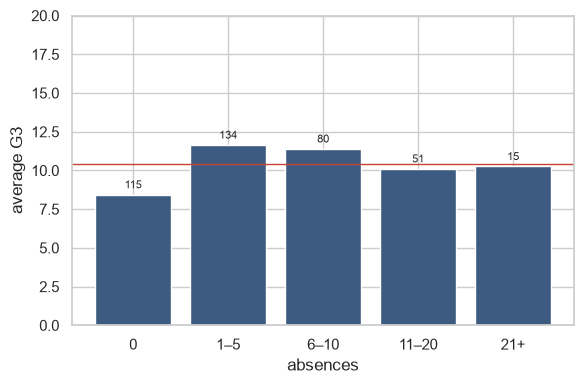

In [153]:
bins = pd.cut(
    df["absences"],
    bins=[-0.1, 0, 5, 10, 20, df["absences"].max()],
    labels=["0", "1–5", "6–10", "11–20", "21+"],
)
absence_means = df.groupby(bins, observed=True)["G3"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(absence_means.index.astype(str), absence_means["mean"], color="#3d5a80")
ax.axhline(float(y.mean()), color="#c44536", linewidth=1)
ax.set_ylim(0, 20)
ax.set_xlabel("absences")
ax.set_ylabel("average G3")
for i, (mean, size) in enumerate(zip(absence_means["mean"], absence_means["size"])):
    ax.text(i, mean + 0.4, str(int(size)), ha="center", fontsize=8)
fig.tight_layout()
plt.show()

## Yes/no columns

Every column with two values. The table is sorted by the gap between the two average grades. The plot draws that same gap. The axis is zoomed in so a small gap stays small. Grades themselves run from 0 to 20, and the red line is the overall average.


In [154]:
rows = []
for col in X.columns:
    if X[col].nunique() != 2:
        continue
    grouped = df.groupby(col, observed=True)["G3"].agg(mean="mean", n="size")
    grouped = grouped.sort_values("mean")
    low, high = grouped.index
    rows.append({
        "column": col,
        "lower grade": f"{low} ({int(grouped.loc[low, 'n'])})",
        "mean, lower": grouped.loc[low, "mean"],
        "higher grade": f"{high} ({int(grouped.loc[high, 'n'])})",
        "mean, higher": grouped.loc[high, "mean"],
        "gap": grouped.loc[high, "mean"] - grouped.loc[low, "mean"],
    })

binary = pd.DataFrame(rows).sort_values("gap", ascending=False).reset_index(drop=True)
binary.round(2)


,column,lower grade,"mean, lower",higher grade,"mean, higher",gap
0,higher,no (20),6.80,yes (375),10.61,3.81
1,romantic,yes (132),9.58,no (263),10.84,1.26
2,internet,no (66),9.41,yes (329),10.62,1.21
3,address,R (88),9.51,U (307),10.67,1.16
4,schoolsup,yes (51),9.43,no (344),10.56,1.13
5,sex,F (208),9.97,M (187),10.91,0.95
6,paid,no (214),9.99,yes (181),10.92,0.94
7,Pstatus,T (354),10.32,A (41),11.20,0.87
8,famsize,GT3 (281),10.18,LE3 (114),11.00,0.82
9,school,MS (46),9.85,GP (349),10.49,0.64


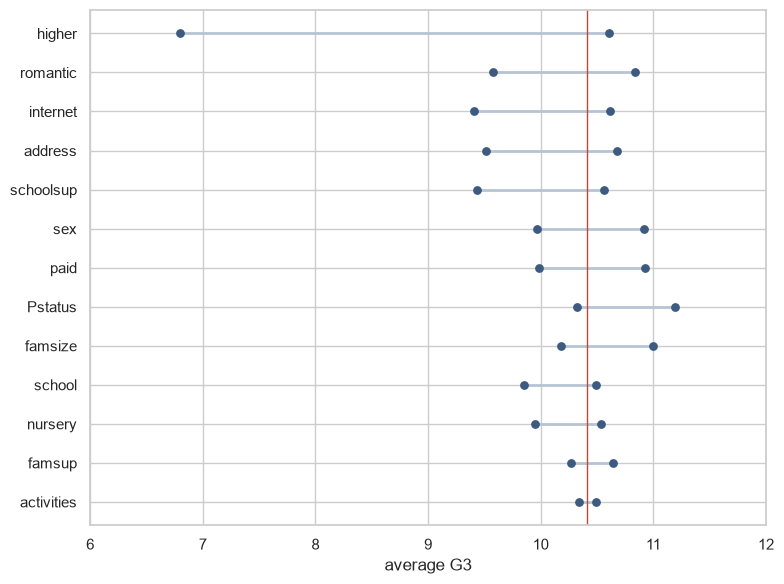

In [155]:
shown = binary.sort_values("gap")
ypos = np.arange(len(shown))

fig, ax = plt.subplots(figsize=(8, 6))
ax.hlines(ypos, shown["mean, lower"], shown["mean, higher"], color="#b7c4d4", linewidth=2)
ax.scatter(shown["mean, lower"], ypos, s=28, color="#3d5a80", zorder=3)
ax.scatter(shown["mean, higher"], ypos, s=28, color="#3d5a80", zorder=3)
ax.axvline(float(y.mean()), color="#c44536", linewidth=1)

ax.set_yticks(ypos)
ax.set_yticklabels(shown["column"])
ax.set_xlabel("average G3")
ax.set_xlim(6, 12)
fig.tight_layout()
plt.show()


## Set aside four nearly flat columns

`activities`, `famsup`, `nursery`, and `school` have group averages within about 0.6 of a grade. Set them aside for this exploration. They could still matter in combination with other columns, so this is a candidate selection rather than proof that they add no information.

In [156]:
X = X.drop(columns=["activities", "famsup", "nursery", "school"])
print(f"{X.shape[1]} columns left")


26 columns left


## Ordered scores

These eleven are short numbered ladders: `Medu`, `Fedu`, `traveltime`, `studytime`, `failures`, `famrel`, `freetime`, `goout`, `Dalc`, `Walc`, `health`.

The table is the average `G3` at each step, with the student count in brackets. The lines underneath are the same numbers. The red line is the overall average, 10.4. A red dot is a step with fewer than 15 students.

`failures` falls at every step: 11.3, 8.1, 6.2, 5.7. `Medu` and `Fedu` climb once the step at 0 is set aside (3 students and 2). `traveltime` falls as the journey gets longer. Its last step is 8 students.

`goout` rises, then falls. `freetime` jumps. `studytime` sits flat, steps up, then sits flat again. `famrel`, `Dalc`, `Walc`, and `health` stay near 10.4. `health` at 1 is higher, and that group has 47 students.

In [157]:
score_cols = [
    "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health",
]

rows = []
for col in score_cols:
    grouped = df.groupby(col, observed=True)["G3"].agg(mean="mean", n="size")
    record = {"column": col}
    for level, row in grouped.iterrows():
        record[str(int(level))] = f"{row['mean']:.1f} ({int(row['n'])})"
    rows.append(record)

scores = pd.DataFrame(rows).set_index("column")
scores

,0,1,2,3,4,5
column,,,,,,
Medu,13.0 (3),8.7 (59),9.7 (103),10.3 (99),11.8 (131),NaN
Fedu,13.0 (2),9.2 (82),10.3 (115),10.7 (100),11.4 (96),NaN
traveltime,NaN,10.8 (257),9.9 (107),9.3 (23),8.8 (8),NaN
studytime,NaN,10.0 (105),10.2 (198),11.4 (65),11.3 (27),NaN
failures,11.3 (312),8.1 (50),6.2 (17),5.7 (16),NaN,NaN
famrel,NaN,10.6 (8),9.9 (18),10.0 (68),10.4 (195),10.8 (106)
freetime,NaN,9.8 (19),11.6 (64),9.8 (157),10.4 (115),11.3 (40)
goout,NaN,9.9 (23),11.2 (103),11.0 (130),9.7 (86),9.0 (53)
Dalc,NaN,10.7 (276),9.3 (75),10.5 (26),9.9 (9),10.7 (9)


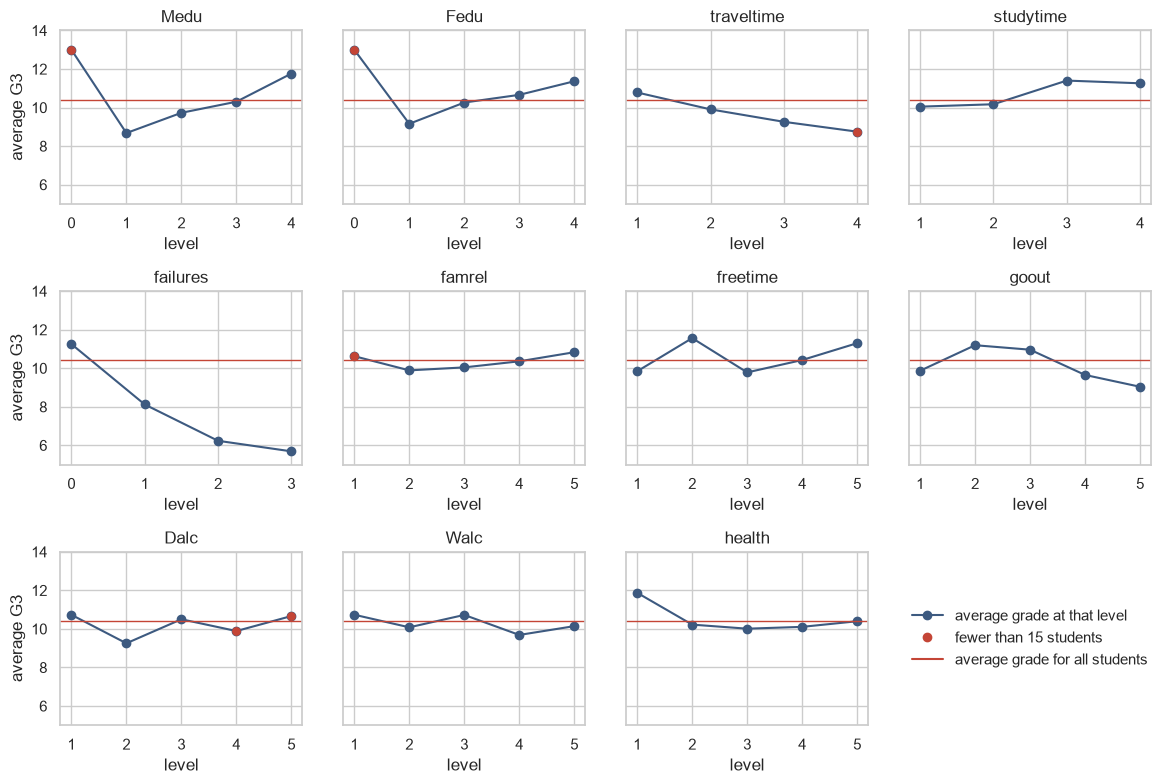

In [158]:
fig, axes = plt.subplots(3, 4, figsize=(12, 8), sharey=True)
axes = axes.ravel()
overall = float(y.mean())

for ax, col in zip(axes, score_cols):
    grouped = df.groupby(col, observed=True)["G3"].agg(mean="mean", n="size").sort_index()
    ax.plot(grouped.index, grouped["mean"], color="#3d5a80", marker="o")
    thin = grouped["n"] < 15
    ax.scatter(grouped.index[thin], grouped.loc[thin, "mean"], color="#c44536", s=28, zorder=3)
    ax.axhline(overall, color="#c44536", linewidth=1)
    ax.set_title(col)
    ax.set_ylim(5, 14)
    ax.set_xlabel("level")

for ax in (axes[0], axes[4], axes[8]):
    ax.set_ylabel("average G3")

axes[-1].axis("off")
axes[-1].legend(
    handles=[
        plt.Line2D([0], [0], color="#3d5a80", marker="o", label="average grade at that level"),
        plt.Line2D([0], [0], color="#c44536", marker="o", linestyle="None", label="fewer than 15 students"),
        plt.Line2D([0], [0], color="#c44536", label="average grade for all students"),
    ],
    loc="center",
    frameon=False,
)
fig.tight_layout()
plt.show()

## What the levels mean

- `Medu` is the mother's education. 0 none, 1 primary (up to 4th grade), 2 from 5th to 9th grade, 3 secondary, 4 higher education.
- `Fedu` is the same scale for the father.
- `traveltime` is how long it takes to get to school. 1 under 15 minutes, 2 from 15 to 30 minutes, 3 from 30 minutes to an hour, 4 over an hour.
- `studytime` is hours of study in a week. 1 under 2 hours, 2 from 2 to 5, 3 from 5 to 10, 4 over 10.
- `failures` is how many classes the student has failed before. This file only has 0, 1, 2, and 3.
- `famrel` is how good the family relationships are. 1 very bad, 5 excellent.
- `freetime` is free time after school. 1 very little, 5 a lot.
- `goout` is how often they go out with friends. 1 very little, 5 a lot.
- `Dalc` is alcohol on weekdays. 1 very little, 5 a lot.
- `Walc` is alcohol at the weekend. Same scale, 1 to 5.
- `health` is how healthy the student is now. 1 very bad, 5 very good.

## Set aside two nearly flat scores

`Walc` and `famrel` sit near the overall average of 10.4. Their best single splits reduce MSE by only about 0.08 and 0.06. Set them aside for the candidate feature set.

Keep `health`: level 1 averages 11.9 from 47 students. Keep `Dalc` too: level 2 averages 9.3 from 75 students, against 10.7 at level 1. These differences are worth testing in a model; they do not establish causes.

In [159]:
X = X.drop(columns=["Walc", "famrel"])
print(f"{X.shape[1]} columns left")

24 columns left


## Jobs, reason, guardian

These four are names, not ladders. Each bar is the average `G3`, and the count is in the table. The red line is the overall average, 10.4.

- `Mjob` is the mother's job: `at_home`, `health`, `services` (office or police, for example), `teacher`, or `other`.
- `Fjob` is the same list for the father.
- `reason` is why the student picked this school: the `course`, close to `home`, the school's `reputation`, or `other`.
- `guardian` is who they live with: `mother`, `father`, or `other`.

`age` and `absences` are the two columns still not looked at on their own.

In [160]:
name_cols = ["Mjob", "Fjob", "reason", "guardian"]

rows = []
for col in name_cols:
    grouped = df.groupby(col, observed=True)["G3"].agg(mean="mean", n="size").sort_values("mean")
    for level, row in grouped.iterrows():
        rows.append({
            "column": col,
            "value": level,
            "n": int(row["n"]),
            "mean G3": row["mean"],
        })

names = pd.DataFrame(rows)
names.round(2)

,column,value,n,mean G3
0,Mjob,at_home,59,9.15
1,Mjob,other,141,9.82
2,Mjob,services,103,11.02
3,Mjob,teacher,58,11.05
4,Mjob,health,34,12.15
5,Fjob,at_home,20,10.15
6,Fjob,other,217,10.19
7,Fjob,services,111,10.30
8,Fjob,health,18,11.61
9,Fjob,teacher,29,11.97


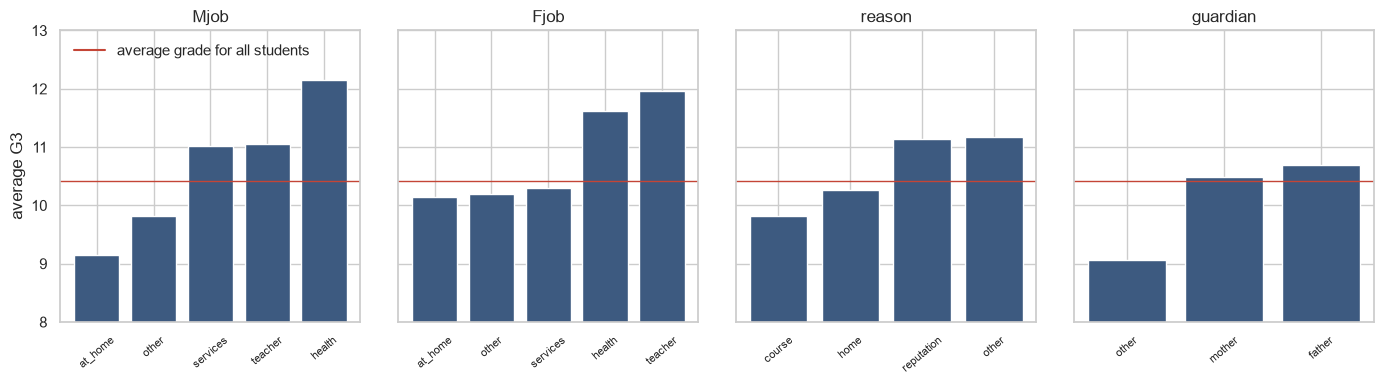

In [161]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
overall = float(y.mean())

for ax, col in zip(axes, name_cols):
    grouped = (
        df.groupby(col, observed=True)["G3"]
        .agg(mean="mean", n="size")
        .sort_values("mean")
    )
    ax.bar(grouped.index.astype(str), grouped["mean"], color="#3d5a80")
    ax.axhline(overall, color="#c44536", linewidth=1)
    ax.set_title(col)
    ax.tick_params(axis="x", labelrotation=40, labelsize=8)
    ax.set_ylim(8, 13)

axes[0].set_ylabel("average G3")
axes[0].legend(
    handles=[plt.Line2D([0], [0], color="#c44536", label="average grade for all students")],
    frameon=False,
    loc="upper left",
)
fig.tight_layout()
plt.show()

## Age and absences

Keep both columns. Ages 15 to 19 show a downward pattern. Ages 20, 21 and 22 have only 3, 1 and 1 students, so those dots are red. Keep those students: a small group makes its average uncertain, not invalid.

Absences are binned for this chart only. Counts appear above the bars. Students with no absences average about 8.4; groups with some absences average higher. This association does not mean that missing school improves grades.

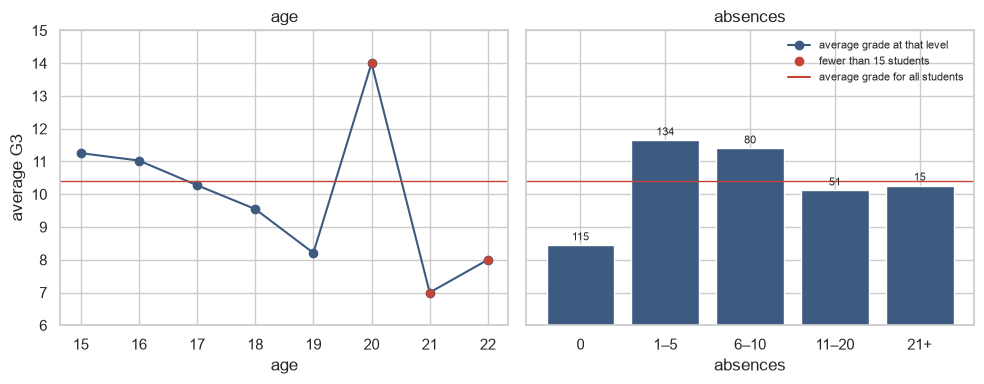

In [162]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
overall = float(y.mean())

age = df.groupby("age", observed=True)["G3"].agg(mean="mean", n="size").sort_index()
axes[0].plot(age.index, age["mean"], color="#3d5a80", marker="o")
thin = age["n"] < 15
axes[0].scatter(age.index[thin], age.loc[thin, "mean"], color="#c44536", s=28, zorder=3)
axes[0].axhline(overall, color="#c44536", linewidth=1)
axes[0].set_title("age")
axes[0].set_xlabel("age")
axes[0].set_ylabel("average G3")
axes[0].set_ylim(6, 15)

bins = pd.cut(
    df["absences"],
    bins=[-0.1, 0, 5, 10, 20, df["absences"].max()],
    labels=["0", "1–5", "6–10", "11–20", "21+"],
)
absence_means = df.groupby(bins, observed=True)["G3"].agg(mean="mean", n="size")
axes[1].bar(absence_means.index.astype(str), absence_means["mean"], color="#3d5a80")
axes[1].axhline(overall, color="#c44536", linewidth=1)
axes[1].set_title("absences")
axes[1].set_xlabel("absences")
for i, (mean, size) in enumerate(zip(absence_means["mean"], absence_means["n"])):
    axes[1].text(i, mean + 0.15, str(int(size)), ha="center", fontsize=8)

axes[1].legend(
    handles=[
        plt.Line2D([0], [0], color="#3d5a80", marker="o", label="average grade at that level"),
        plt.Line2D([0], [0], color="#c44536", marker="o", linestyle="None", label="fewer than 15 students"),
        plt.Line2D([0], [0], color="#c44536", label="average grade for all students"),
    ],
    frameon=False,
    fontsize=8,
    loc="upper right",
)
fig.tight_layout()
plt.show()

## Candidate feature set

All **395 students** remain. After excluding `G1` and `G2`, the investigation sets aside six inputs: `activities`, `famsup`, `nursery`, `school`, `Walc`, and `famrel`. That leaves **24 candidate inputs**.

The 13 text columns are `sex`, `address`, `famsize`, `Pstatus`, `Mjob`, `Fjob`, `reason`, `guardian`, `schoolsup`, `paid`, `higher`, `internet`, and `romantic`. Model pipelines can one-hot encode them.

The 11 numeric columns are `age`, `absences`, `Medu`, `Fedu`, `traveltime`, `studytime`, `failures`, `freetime`, `goout`, `Dalc`, and `health`. Absences stay numeric; the bins above are only for plotting.

These choices are based on the charts above. Their effect on prediction error needs to be checked with cross-validation.